In [1]:
# -*- coding: utf-8 -*-
# import statements

import sys
import os
import numpy as np
import pandas as pd
from PyQt5.QtWidgets import QFileDialog, QApplication
import matplotlib as mpl
from matplotlib import pyplot as plt

# enable copy-on-write mode for Pandas (will be default from Pandas 3.0)
pd.options.mode.copy_on_write = True

In [2]:
# set plot parameters
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = 'Times New Roman'
mpl.rcParams.update({'font.size': 16})
mpl.rcParams['figure.autolayout'] = True
mpl.rcParams['mathtext.fontset'] = 'stix'

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE,
       labelsize=MEDIUM_SIZE)    # fontsize of the axes title and x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

mycolours = [(0, 102, 255), (0, 204, 153), (255, 0, 102), (74, 111, 152),
             (251, 164, 49), (204, 153, 255), (90, 192, 255), (80, 245, 233),
             (255, 90, 192), (164, 201, 242), (255, 254, 139), (255, 243, 255)]
mycolours = [tuple(shade/255 for shade in colour) for colour in mycolours]

# enable copy-on-write mode for Pandas (will be default from Pandas 3.0)
pd.options.mode.copy_on_write = True

# check/open QApplication instance
if not QApplication.instance():
    app = QApplication(sys.argv)
else:
    app = QApplication.instance() 



Set the saveplots toggle to True if plot saving is desired:

In [3]:
saveplots = True

if saveplots:
    # select figure output save path
    outFigPath = QFileDialog.getExistingDirectory(caption=r"Select output folder to save plots '03 Experiment\Experiment 2\Analysis\Plots'")

    # create subfolders if not already existing
    try:
        os.mkdir(os.path.join(outFigPath, "svg"))
    except FileExistsError:
        pass

    try:
        os.mkdir(os.path.join(outFigPath, "pdf"))
    except FileExistsError:
        pass


# Import data

In [53]:
dAnnoy_CV_res_path = list(QFileDialog.getOpenFileName(filter="dAnnoy_CV_results.csv",
                                                       caption=r"Open dAnnoy_CV_results.csv in: \03 Experiment\Experiment 2\Analysis\R"))[0]
dAnnoy_CV_res = pd.read_csv(dAnnoy_CV_res_path, index_col=0)

dHiAnnoy_CV_res_path = list(QFileDialog.getOpenFileName(filter="dHiAnnoy_CV_results.csv",
                                                          caption=r"Open dHiAnnoy_CV_results.csv in: \03 Experiment\Experiment 2\Analysis\R"))[0]
dHiAnnoy_CV_res = pd.read_csv(dHiAnnoy_CV_res_path, index_col=0)

In [54]:
dAnnoy_CV_res_filt = dAnnoy_CV_res.drop(labels=["m9h"])

dAnnoy_CV_res_filt['Scenario'] = ["Benchmark", "I", "II", "III", "IV", "V", "VI", "VII", "VIII"]

dAnnoy_CV_res_filt.set_index(keys='Scenario', inplace=True)

dHiAnnoy_CV_res_filt = dHiAnnoy_CV_res.drop(labels=["m20d"])

dHiAnnoy_CV_res_filt['Scenario'] = ["Benchmark", "I", "II", "III", "IV", "V", "VI", "VII", "VIII"]

dHiAnnoy_CV_res_filt.set_index(keys='Scenario', inplace=True)

In [55]:
dAnnoy_CV_res_filt["dRMSE"] = dAnnoy_CV_res_filt.loc['Benchmark', 'rmse_raw'] - dAnnoy_CV_res_filt['rmse_raw']
dAnnoy_CV_res_filt["dR2"] = dAnnoy_CV_res_filt['r2_cv_raw'] - dAnnoy_CV_res_filt.loc['Benchmark', 'r2_cv_raw']

dHiAnnoy_CV_res_filt["dRMSE"] = dHiAnnoy_CV_res_filt.loc['Benchmark', 'rmse'] - dHiAnnoy_CV_res_filt['rmse']
dHiAnnoy_CV_res_filt["dR2"] = dHiAnnoy_CV_res_filt['r2_cv'] - dHiAnnoy_CV_res_filt.loc['Benchmark', 'r2_cv']


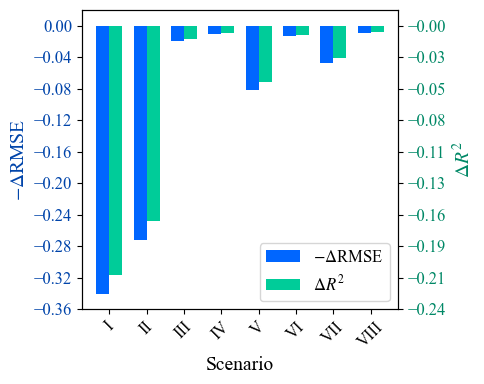

In [56]:
# plot dRMSE and dR2 for each scenario (except Benchmark) as bar plots with adjacent grouped bars,
# with dRMSE on the left y-axis and dR2 on the right y-axis, and save as svg and pdf

data = dAnnoy_CV_res_filt.drop(labels=["Benchmark"], axis=0)

# 1. Setup positions based on the DataFrame index length
x = np.arange(len(data.index))   # Numerical positions for the bars
width = 0.35                      # Width of each individual bar

# 2. Initialize the plot and primary axis (Left)
fig, ax1 = plt.subplots(figsize=(5, 4))

# 3. Plot dRMSE on the primary left axis (shifted left)
bar1 = ax1.bar(x - width/2, data['dRMSE'], width, label='$-\Delta$RMSE', color=mycolours[0])
ax1.set_xlabel('Scenario')
ax1.set_ylabel('$-\Delta$RMSE', color=np.array(mycolours[0])/1.5)
ax1.tick_params(axis='y', labelcolor=np.array(mycolours[0])/1.5)

# 4. Create and plot dR2 on the secondary right axis (shifted right)
ax2 = ax1.twinx()
bar2 = ax2.bar(x + width/2, data['dR2'], width, label='$\Delta R^2$', color=mycolours[1])
ax2.set_ylabel('$\Delta R^2$', color=np.array(mycolours[1])/1.5)
ax2.tick_params(axis='y', labelcolor=np.array(mycolours[1])/1.5)

# 5. Set x-axis tick positions and map your DataFrame index labels
ax1.set_xticks(x)
ax1.set_xticklabels(data.index, rotation=45, ha='center')  # Rotated for readability

# 6. Unify the legends from both axes into one box
bars = [bar1, bar2]
labels = [b.get_label() for b in bars]
ax1.legend(bars, labels, loc='lower right')

# ensure both axes have their y-origin aligned by setting equivalent y-limits
ax1_limits = np.array([-0.36, 0.02])
axis_scale = 1.5
ax1.set_ylim(ax1_limits)
ax2.set_ylim(ax1_limits/axis_scale)

ax1_yticks = np.arange(-0.36, 0.03, 0.04)
ax1.set_yticks(ax1_yticks)
ax2.set_yticks(ticks=ax1_yticks/axis_scale, labels=[f"{tick:.2f}".replace('-', '\u2212') for tick in ax1_yticks/axis_scale])

fig.tight_layout()

if saveplots:

    filename = 'dAnnoy_CV_results'

    plt.savefig(os.path.join(outFigPath, 'svg', f'{filename}.svg'))
    plt.savefig(os.path.join(outFigPath, 'pdf', f'{filename}.pdf'))

plt.show()


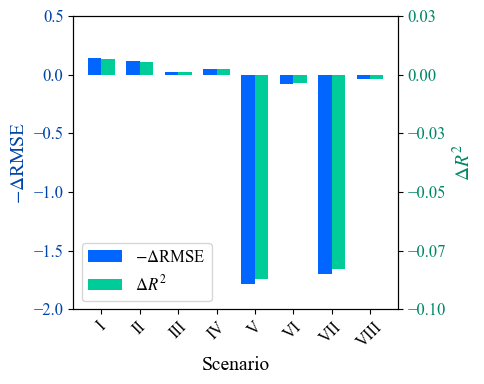

In [57]:
# plot dRMSE and dR2 for each scenario (except Benchmark) as bar plots with adjacent grouped bars,
# with dRMSE on the left y-axis and dR2 on the right y-axis, and save as svg and pdf

data = dHiAnnoy_CV_res_filt.drop(labels=["Benchmark"], axis=0)

# 1. Setup positions based on the DataFrame index length
x = np.arange(len(data.index))   # Numerical positions for the bars
width = 0.35                      # Width of each individual bar

# 2. Initialize the plot and primary axis (Left)
fig, ax1 = plt.subplots(figsize=(5, 4))

# 3. Plot dRMSE on the primary left axis (shifted left)
bar1 = ax1.bar(x - width/2, 100*data['dRMSE'], width, label='$-\Delta$RMSE', color=mycolours[0])
ax1.set_xlabel('Scenario')
ax1.set_ylabel('$-\Delta$RMSE', color=np.array(mycolours[0])/1.5)
ax1.tick_params(axis='y', labelcolor=np.array(mycolours[0])/1.5)

# 4. Create and plot dR2 on the secondary right axis (shifted right)
ax2 = ax1.twinx()
bar2 = ax2.bar(x + width/2, data['dR2'], width, label='$\Delta R^2$', color=mycolours[1])
ax2.set_ylabel('$\Delta R^2$', color=np.array(mycolours[1])/1.5)
ax2.tick_params(axis='y', labelcolor=np.array(mycolours[1])/1.5)

# 5. Set x-axis tick positions and map your DataFrame index labels
ax1.set_xticks(x)
ax1.set_xticklabels(data.index, rotation=45, ha='center')  # Rotated for readability

# 6. Unify the legends from both axes into one box
bars = [bar1, bar2]
labels = [b.get_label() for b in bars]
ax1.legend(bars, labels, loc='lower left')

# ensure both axes have their y-origin aligned by setting equivalent y-limits
ax1_limits = np.array([-2., 0.5])
axis_scale = 1/0.05
ax1.set_ylim(ax1_limits)
ax2.set_ylim(ax1_limits/axis_scale)

ax1_yticks = np.arange(-2., 0.6, 0.5)
ax1.set_yticks(ax1_yticks)
ax2.set_yticks(ticks=ax1_yticks/axis_scale, labels=[f"{tick:.2f}".replace('-', '\u2212') for tick in ax1_yticks/axis_scale])

fig.tight_layout()

if saveplots:

    filename = 'dHiAnnoy_CV_results'

    plt.savefig(os.path.join(outFigPath, 'svg', f'{filename}.svg'))
    plt.savefig(os.path.join(outFigPath, 'pdf', f'{filename}.pdf'))

plt.show()
